# 03 — Model experimentation and comparison

Five models from five algorithm families, all trained and evaluated by the same harness
(`pathsnap/models/evaluate.py`, run with `python -m pathsnap.models.train`).

**Protocol**
- Data: reliable rows of `data/processed/<partition>_candidates.parquet`; X = 16 features, y = 1 if the candidate is the true arc.
- Cross-validation: 5-fold `GroupKFold` over the **80 train trips**, grouped by `trip_id` (no trip in both fit and validation).
- Development test: refit on all train, evaluate on the **10 student_test trips**.
- Untuned (default-style) configurations here; Bayesian optimisation of the chosen model is a separate step.
- Evaluator-test data is not used.

**Metrics**: macro F1, precision, recall, log loss (per candidate row, threshold 0.5); observation-level Top-1 accuracy
(per GPS point, the highest-scoring candidate is the true arc); route continuity (consecutive predicted arcs identical
or connected); training and inference time.

In [1]:
# --- setup: find the repo, check data and trained models ---
import sys, pathlib, subprocess, json
ROOT = pathlib.Path.cwd().resolve()
while not (ROOT / "pathsnap" / "config.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / "pathsnap" / "config.py").exists():
    raise RuntimeError("Run this notebook from inside the cloned repo (its notebooks/ folder).")
sys.path.insert(0, str(ROOT))
from pathsnap.reproduce import ensure_processed, models_ready
from pathsnap.models.registry import RECOMMENDED
ensure_processed()                # builds data/processed/* if missing (~1 min)

# Trained models are not in git (weights are large). Missing ones are trained here when this
# flag is True; the recommended five take ~30-40 min on an 8-core laptop.
TRAIN_IF_MISSING = True
missing = models_ready(RECOMMENDED)
if missing and TRAIN_IF_MISSING:
    print("training missing models:", missing)
    subprocess.run([sys.executable, "-m", "pathsnap.models.train", *missing], cwd=ROOT, check=True)
elif missing:
    raise RuntimeError(f"Models not trained yet: {missing}. Run: python -m pathsnap.models.train")
print("models OK:", RECOMMENDED)

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from pathsnap.config import RESULTS_DIR, ARTIFACTS_DIR, SEED
from pathsnap.features.candidates import FEATURE_COLUMNS
from pathsnap.models.evaluate import load_candidates, subsample_points, evaluate
from pathsnap.models.registry import REGISTRY
from pathsnap.viz import model_plots

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)
plt.rcParams["figure.dpi"] = 110
MD = RESULTS_DIR / "models"

raw data OK: /run/media/amogh-herle/DATA/PESU/ML_LAB/HACKATHON/Student folder  {'train': 80, 'student_test': 10}
processed data OK: /run/media/amogh-herle/DATA/PESU/ML_LAB/HACKATHON/pathsnap/data/processed
models OK: ['logreg', 'knn', 'rf', 'lgbm', 'mlp']


## 1. Configurations

In [2]:
comp = pd.read_csv(MD / "comparison.csv")
models = comp["model"].tolist()
meta = {m: json.loads((MD / m / "metrics.json").read_text()) for m in models}   # saved with each run
pd.DataFrame([{"model": m, "family": meta[m]["family"], "configuration": meta[m]["description"],
               "train_fraction": meta[m]["train_fraction"], "notes": " ".join(meta[m]["notes"])}
              for m in models])

,model,family,configuration,train_fraction,notes
0,xgb_tuned,Boosting,"XGBoost tuned by Optuna TPE: n_estimators=400,...",1.0,best of 50 Optuna trials (objective: CV top-1)
1,rf,Ensemble (bagging),"RandomForest(200 trees, min_samples_leaf=5, ma...",1.0,
2,xgb,Boosting,"XGBoost(400 trees, lr=0.05, max_depth=6, hist)",1.0,
3,lgbm,Boosting,"LightGBM(400 trees, lr=0.05, num_leaves=63)",1.0,
4,dtree,Tree-based,"DecisionTree(max_depth=12, min_samples_leaf=20)",1.0,
5,mlp,Neural network,"StandardScaler + MLP(64-32, ReLU, Adam, early ...",1.0,early_stopping holds out a random 10% of train...
6,knn,Instance-based,"StandardScaler + KNN(k=25, distance-weighted),...",0.1,KNN prediction cost grows with training size; ...
7,logreg,Linear / probabilistic,"StandardScaler + LogisticRegression(C=1.0, lbfgs)",1.0,


## 2. Consolidated comparison

In [3]:
table = comp[["model", "family", "cv_macro_f1", "cv_macro_f1_std", "cv_top1", "cv_row_accuracy",
              "test_top1", "test_row_accuracy", "test_macro_f1",
              "test_precision_macro", "test_recall_macro", "test_log_loss", "test_route_continuity",
              "fit_seconds", "inference_ms_per_1000_points"]].sort_values("cv_macro_f1", ascending=False)
table.round(4)

,model,family,cv_macro_f1,cv_macro_f1_std,cv_top1,cv_row_accuracy,test_top1,test_row_accuracy,test_macro_f1,test_precision_macro,test_recall_macro,test_log_loss,test_route_continuity,fit_seconds,inference_ms_per_1000_points
0,xgb_tuned,Boosting,0.9108,0.0265,0.8515,0.9573,0.8585,0.9630,0.9173,0.9220,0.9128,0.0959,0.9462,11.7950,12.0794
1,rf,Ensemble (bagging),0.9104,0.0268,0.8507,0.9573,0.8587,0.9631,0.9174,0.9232,0.9118,0.0961,0.9458,137.9111,37.0882
2,xgb,Boosting,0.9092,0.0274,0.8489,0.9563,0.8596,0.9631,0.9179,0.9212,0.9146,0.0954,0.9458,12.1196,8.4378
3,lgbm,Boosting,0.9080,0.0287,0.8474,0.9556,0.8582,0.9626,0.9170,0.9196,0.9144,0.0989,0.9427,13.5229,28.9166
4,dtree,Tree-based,0.9048,0.0254,0.8416,0.9542,0.8589,0.9625,0.9164,0.9207,0.9123,0.1066,0.9382,15.8915,1.2447
5,mlp,Neural network,0.9016,0.0300,0.8393,0.9527,0.8573,0.9617,0.9145,0.9187,0.9104,0.1036,0.9434,197.8680,4.4570
6,knn,Instance-based,0.8937,0.0238,0.8311,0.9496,0.8364,0.9553,0.8994,0.9074,0.8919,0.1671,0.9415,0.0505,673.7087
7,logreg,Linear / probabilistic,0.8928,0.0232,0.8397,0.9489,0.8455,0.9551,0.8999,0.9035,0.8963,0.1301,0.9277,1.7605,1.2855


## 3. Stability across folds

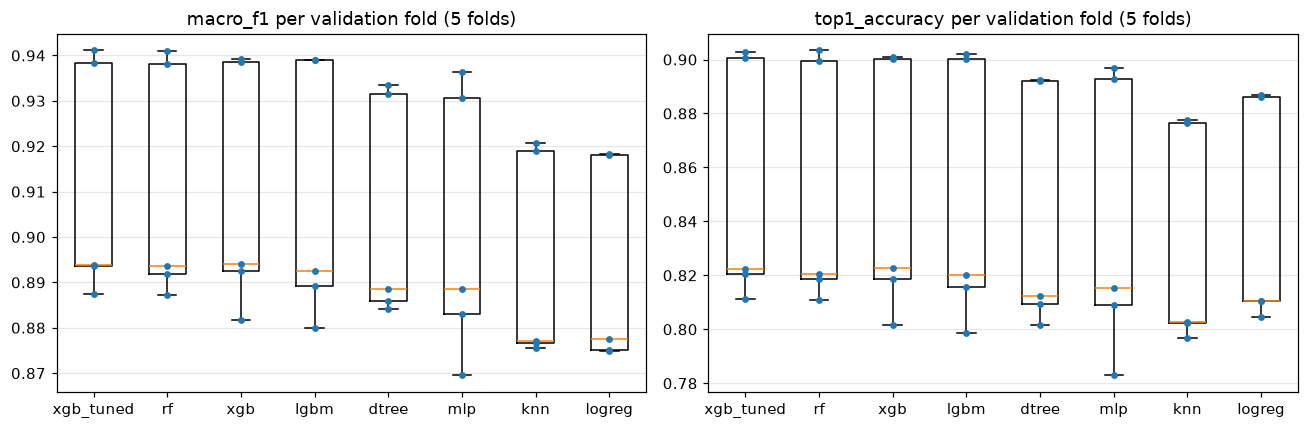

model,dtree,knn,lgbm,logreg,mlp,rf,xgb,xgb_tuned
fold,,,,,,,,
0,0.8095,0.8024,0.8156,0.8105,0.8089,0.8188,0.8187,0.8204
1,0.8924,0.8763,0.9022,0.8860,0.8926,0.8996,0.9002,0.9005
2,0.8922,0.8776,0.9002,0.8868,0.8970,0.9034,0.9010,0.9029
3,0.8125,0.8026,0.8202,0.8106,0.8153,0.8207,0.8226,0.8222
4,0.8015,0.7967,0.7987,0.8045,0.7829,0.8110,0.8017,0.8113


In [4]:
folds = pd.concat([pd.read_csv(MD / m / "cv_folds.csv").assign(model=m) for m in models])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
order = table["model"].tolist()
for ax, metric in zip(axes, ["macro_f1", "top1_accuracy"]):
    data = [folds.loc[folds.model == m, metric] for m in order]
    ax.boxplot(data, tick_labels=order)
    for i, d in enumerate(data, start=1):
        ax.scatter(np.full(len(d), i), d, s=12, color="#1f77b4", zorder=3)
    ax.set_title(f"{metric} per validation fold (5 folds)"); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()
folds.pivot_table(index="fold", columns="model", values="top1_accuracy").round(4)

Fold-to-fold variation is larger than most gaps between models: some trips are much harder than others, so the mean alone is not enough to rank models.

## 4. Comparison plots (generated from the saved results by `pathsnap/viz/model_plots.py`)

plots -> /run/media/amogh-herle/DATA/PESU/ML_LAB/HACKATHON/pathsnap/results/models/plots


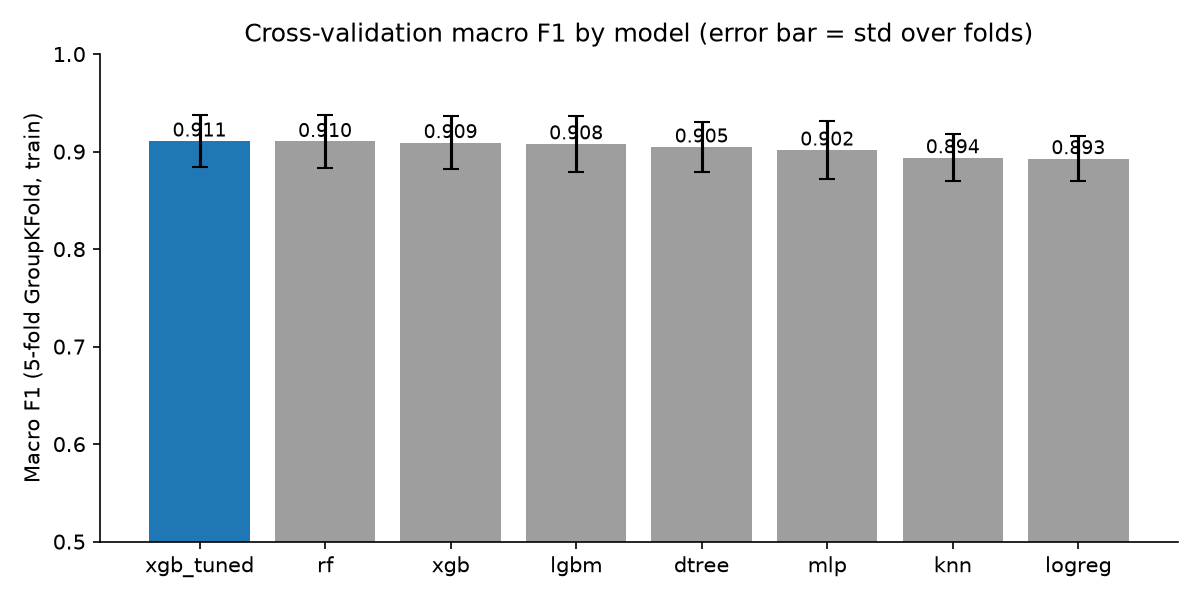

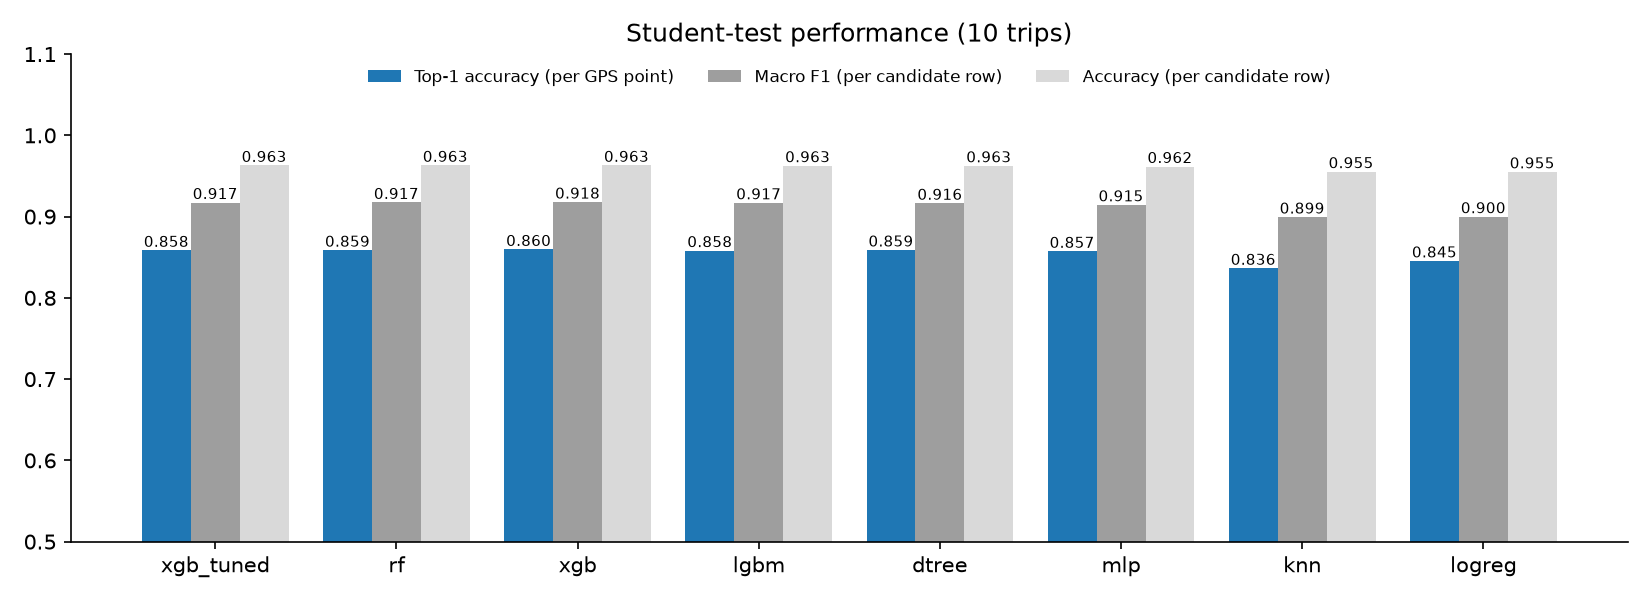

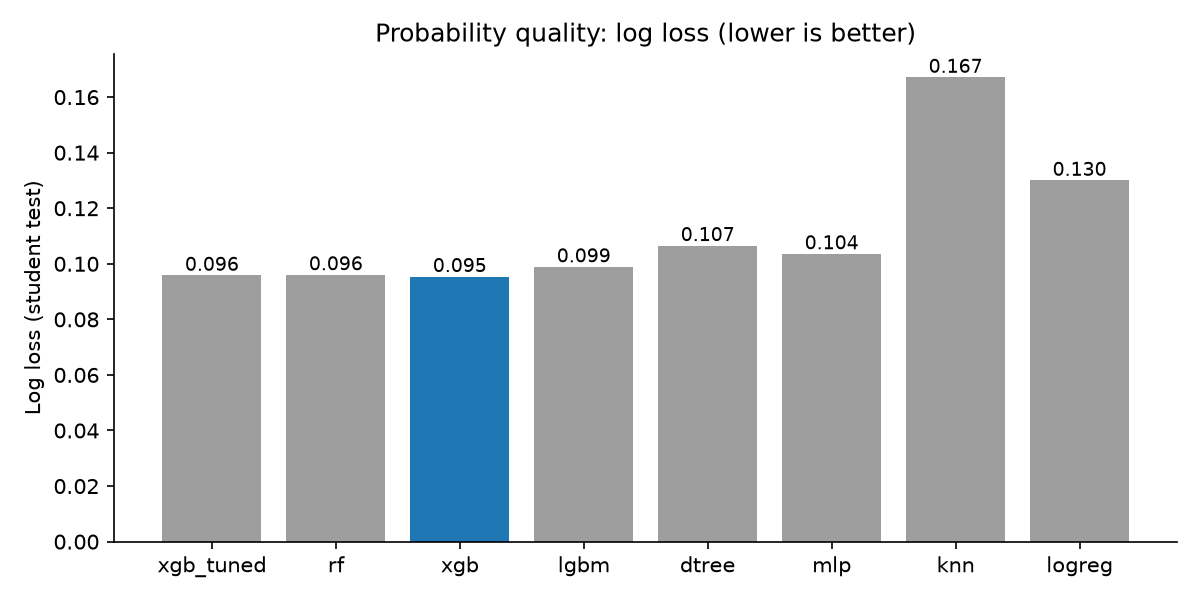

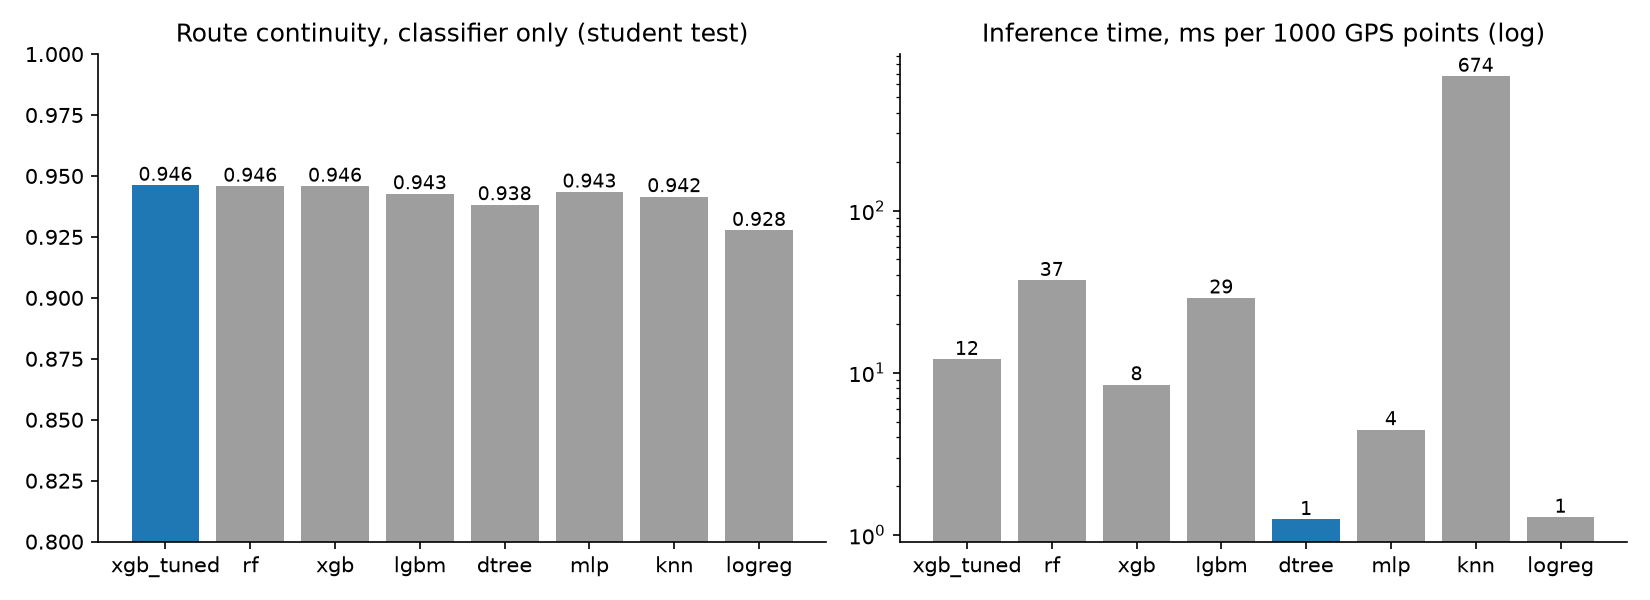

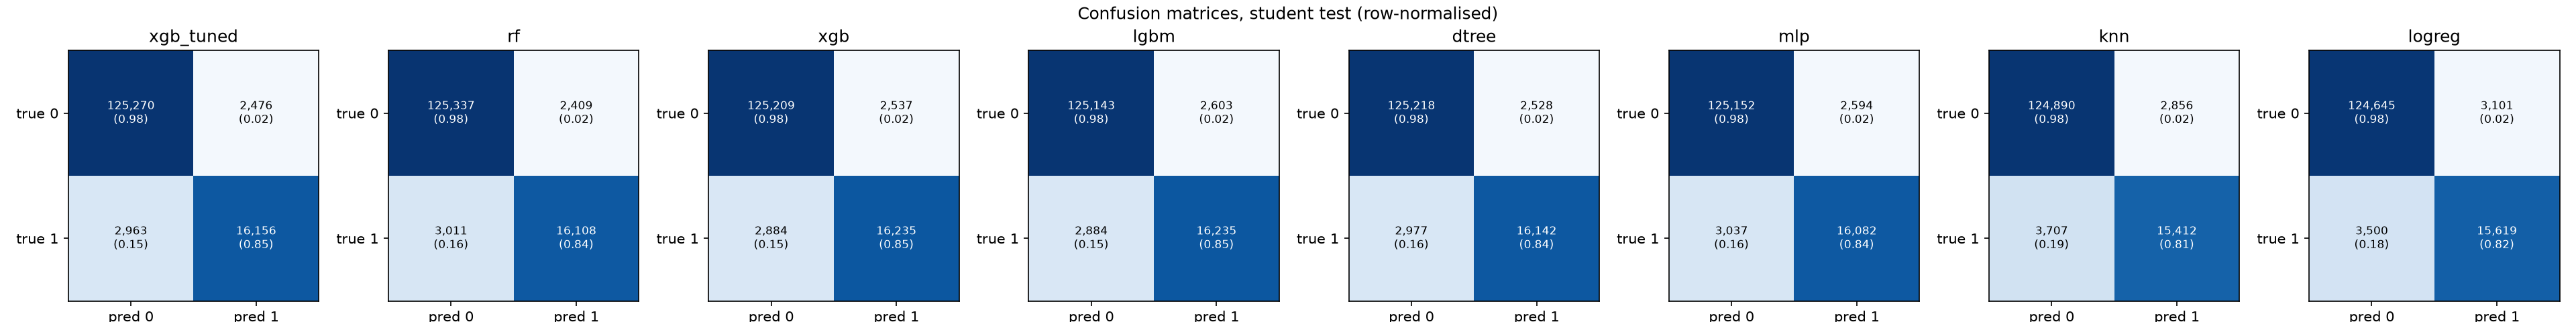

In [5]:
model_plots.main()
for f in ["cv_macro_f1.png", "student_test_top1_f1.png", "log_loss.png", "continuity_inference.png",
          "confusion_matrices.png"]:
    display(Image(filename=str(MD / "plots" / f)))

## 5. Overfitting / underfitting check

Each final model (fitted on all train) is scored on a 20% sample of train GPS points and compared with its cross-validation and student-test scores. A large train-vs-validation gap indicates overfitting; low scores everywhere indicate underfitting.

In [6]:
train = load_candidates("train")
train_s = subsample_points(train, 0.2, seed=SEED)
rows = []
for m in models:
    est = joblib.load(ARTIFACTS_DIR / "models" / f"{m}.joblib")
    proba = est.predict_proba(train_s[FEATURE_COLUMNS].to_numpy())[:, 1]
    tr = evaluate(train_s, proba)
    r = comp.set_index("model").loc[m]
    rows.append({"model": m, "train_top1": tr["top1_accuracy"], "cv_top1": r.cv_top1, "test_top1": r.test_top1,
                 "train_macro_f1": tr["macro_f1"], "cv_macro_f1": r.cv_macro_f1,
                 "train_log_loss": tr["log_loss"], "cv_log_loss": r.cv_log_loss})
fit = pd.DataFrame(rows)
fit["top1_gap_train_minus_cv"] = fit.train_top1 - fit.cv_top1
fit.round(4)

,model,train_top1,cv_top1,test_top1,train_macro_f1,cv_macro_f1,train_log_loss,cv_log_loss,top1_gap_train_minus_cv
0,xgb_tuned,0.8734,0.8515,0.8585,0.9249,0.9108,0.0933,0.1111,0.0219
1,rf,0.9275,0.8507,0.8587,0.9549,0.9104,0.0585,0.1139,0.0769
2,xgb,0.8798,0.8489,0.8596,0.9293,0.9092,0.0879,0.1140,0.0310
3,lgbm,0.8926,0.8474,0.8582,0.9355,0.9080,0.0796,0.1175,0.0452
4,dtree,0.8703,0.8416,0.8589,0.9202,0.9048,0.0991,0.1478,0.0287
5,mlp,0.8753,0.8393,0.8573,0.9243,0.9016,0.0943,0.1290,0.0360
6,knn,0.9229,0.8311,0.8364,0.9541,0.8937,0.0763,0.1928,0.0917
7,logreg,0.8375,0.8397,0.8455,0.8934,0.8928,0.1477,0.1482,-0.0022


## 6. Training history (only models that train by epochs)

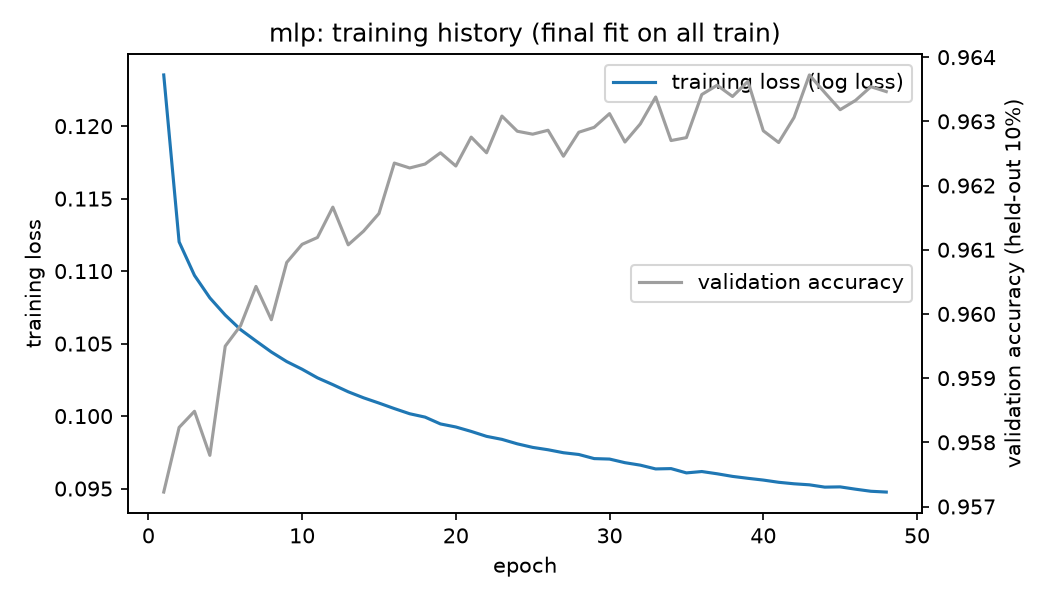

mlp: 48 epochs, final training loss 0.0948
models without epoch-wise history (no curve drawn): ['xgb_tuned', 'rf', 'xgb', 'lgbm', 'dtree', 'knn', 'logreg']


In [7]:
curves = [m for m in models if (MD / m / "loss_curve.csv").exists()]
for m in curves:
    display(Image(filename=str(MD / "plots" / f"{m}_training_curve.png")))
    c = pd.read_csv(MD / m / "loss_curve.csv")
    print(f"{m}: {len(c)} epochs, final training loss {c.train_loss.iloc[-1]:.4f}")
print("models without epoch-wise history (no curve drawn):", [m for m in models if m not in curves])

## 7. Feature importance (tree models)

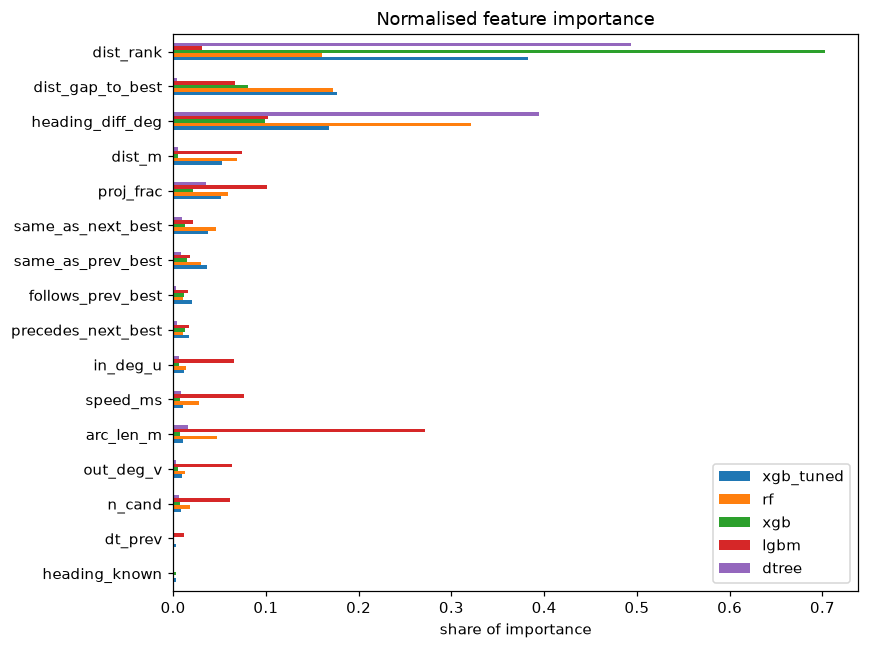

,xgb_tuned,rf,xgb,lgbm,dtree
dist_rank,0.3825,0.1606,0.7032,0.0312,0.4938
dist_gap_to_best,0.1763,0.1719,0.0806,0.0668,0.0039
heading_diff_deg,0.1680,0.3207,0.0990,0.1021,0.3941
dist_m,0.0522,0.0684,0.0056,0.0746,0.0052
proj_frac,0.0520,0.0592,0.0219,0.1009,0.0360
same_as_next_best,0.0372,0.0459,0.0124,0.0218,0.0095
same_as_prev_best,0.0367,0.0301,0.0147,0.0184,0.0081
follows_prev_best,0.0205,0.0108,0.0113,0.0160,0.0036
precedes_next_best,0.0171,0.0107,0.0128,0.0171,0.0047
in_deg_u,0.0122,0.0141,0.0066,0.0660,0.0068


In [8]:
imp = {}
for m in models:
    est = joblib.load(ARTIFACTS_DIR / "models" / f"{m}.joblib")
    final = est[-1] if hasattr(est, "steps") else est
    if hasattr(final, "feature_importances_"):
        v = np.asarray(final.feature_importances_, dtype=float)
        imp[m] = v / v.sum()
if imp:
    imp_df = pd.DataFrame(imp, index=FEATURE_COLUMNS).sort_values(list(imp)[0], ascending=True)
    imp_df.plot.barh(figsize=(8, 6)); plt.title("Normalised feature importance"); plt.xlabel("share of importance")
    plt.tight_layout(); plt.show()
    display(imp_df.sort_values(list(imp)[0], ascending=False).round(4))

## 8. Ranking for model selection

Primary metric: **observation-level Top-1 accuracy** (the task is choosing the right arc per GPS point).
Secondary: **log loss**, because the HMM uses the predicted probabilities as emission scores, so calibration matters.
Also considered: stability across folds, inference speed (the API must answer quickly), and model complexity.

In [9]:
rank = table.set_index("model")[["cv_top1", "test_top1", "cv_macro_f1", "test_log_loss",
                                  "inference_ms_per_1000_points"]].copy()
rank["cv_top1_std"] = folds.groupby("model")["top1_accuracy"].std()
rank.sort_values(["cv_top1"], ascending=False).round(4)

,cv_top1,test_top1,cv_macro_f1,test_log_loss,inference_ms_per_1000_points,cv_top1_std
model,,,,,,
xgb_tuned,0.8515,0.8585,0.9108,0.0959,12.0794,0.0461
rf,0.8507,0.8587,0.9104,0.0961,37.0882,0.0465
xgb,0.8489,0.8596,0.9092,0.0954,8.4378,0.0479
lgbm,0.8474,0.8582,0.9080,0.0989,28.9166,0.0498
dtree,0.8416,0.8589,0.9048,0.1066,1.2447,0.0464
logreg,0.8397,0.8455,0.8928,0.1301,1.2855,0.0427
mlp,0.8393,0.8573,0.9016,0.1036,4.4570,0.0521
knn,0.8311,0.8364,0.8937,0.1671,673.7087,0.0419
